# [18.1] Concept Bottlenecks, Backpacks and Interchange Intervention Training (exercises)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter18_intrinsic_interpretability/exercises/part1_concept_bottlenecks_backpacks_iit/18.1_Concept_Bottlenecks_Backpacks_and_Interchange_Intervention_Training_exercises.ipynb)
> |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter18_intrinsic_interpretability/exercises/part1_concept_bottlenecks_backpacks_iit/18.1_Concept_Bottlenecks_Backpacks_and_Interchange_Intervention_Training_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-12.png" width="350">

# Introduction

A blue triangle is rejected by a classifier. You change its *triangle* concept to “round” and the answer changes. Does this prove the classifier reasons in the concepts you named? What if its “blue” probability secretly carries the original shape?

By the end of this notebook, you will have shown that a concept intervention, a fixed-sense language readout, and an interchange-trained causal readout have different promises. Your evidence will be a controlled intervention dashboard on exact finite tasks, with thresholded concepts, wrong-sense edits and wrong-subspace interchanges beside the intended operations.

This is a CPU study edition. The bottleneck and Backpack computations are faithful small mathematical components with supplied parameters, **not trained image or language models**. The IIT component fits a two-parameter readout to a tiny analytic counterfactual dataset; it is not the paper’s neural benchmark or a DAS validation. You can inspect every number. The open question is when these components remain meaningful after learning them at scale.

Prerequisites: array broadcasting, matrix multiplication, least squares and activation patching (1.2); causal abstraction and rotated subspaces (11.3) help with the final part.

## Content & Learning Objectives

### 1️⃣ Concepts you can correct
A bottleneck is useful only if its coordinates behave like the concepts they name.
> ##### Learning Objectives
> - Implement concept probabilities, a downstream readout, and coordinate corrections.
> - Construct and diagnose leakage that survives perfect thresholded concept accuracy.

### 2️⃣ Contextual mixtures of fixed senses
A word’s stored sense vectors remain fixed while context changes their weighted contribution.
> ##### Learning Objectives
> - Implement causal contextual weights, fixed-sense mixing and linear output projections.
> - Predict the exact effect of a sense edit and measure its collateral effect.

### 3️⃣ Train for counterfactuals
Observationally identical solutions may disagree when internal states are swapped.
> ##### Learning Objectives
> - Construct high-level interchange targets and a differentiable subspace replacement.
> - Fit a tiny readout on counterfactual rows and compare with observation-only fitting.

### 4️⃣ Audit the intervention
A successful patch should survive all ordered base/donor pairs, with a negative alignment control.
> ##### Learning Objectives
> - Measure interchange agreement and visualize where an observational shortcut fails.
> - Predict a changed causal rule before recomputing the tiny fit.

### ☆ Bonus
Relate these exact components to learned concept models, released Backpack weights and DAS.

## Setup code

Use the existing course environment. No downloads, pretrained weights or accelerator are required. NumPy float64 makes every small matrix operation inspectable. Run from the repository or this chapter’s exercises directory. The setup discovers the chapter without relying on your current notebook filename.

In [ ]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
_root = next((p for p in _candidates if (p / "chapter18_intrinsic_interpretability" / "exercises").exists()), None)
if _root is not None:
    exercises_dir = _root / "chapter18_intrinsic_interpretability" / "exercises"
else:
    exercises_dir = next(p for p in _candidates if (p / "part1_concept_bottlenecks_backpacks_iit").exists())
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
from part1_concept_bottlenecks_backpacks_iit import tests as tests
MAIN = __name__ == "__main__"
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ Concepts you can correct

> ##### Learning Objectives
>
> - Construct and diagnose leakage that survives perfect thresholded concept accuracy.

Our finite world has binary concepts $c=(\mathrm{blue},\mathrm{round})$ and label $y=\mathrm{round}$. An image encoder would estimate $g(x)$; here we supply its two scores so we can isolate the *bottleneck contract*. The downstream readout is $f(\hat c)=\hat c W+b$; weights have shape `[concept, output]` and concept arrays have shape `[batch, concept]`. A correction changes just one coordinate and then reruns the same readout. It does not change the input or retrain anything.

First implement an ordinary sigmoid. Stable evaluation matters even in teaching fixtures: `exp(1000)` need not overflow to teach a concept.

### Exercise - implement `concept_probabilities`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Map arbitrary real concept scores to probabilities with the same shape. The endpoints should approach zero and one without overflow; zero maps to 0.5.

In [ ]:
def concept_probabilities(scores):
    raise NotImplementedError()


tests.test_concept_probabilities(concept_probabilities)

<details><summary>Hint</summary>

Use `logaddexp(0, -scores)` for the negative log-sigmoid.

</details>

<details><summary>Help - why does this matter?</summary>

The bottleneck values are continuous probabilities, not automatically discrete symbols. This distinction will create our leakage counterexample.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_concept_probabilities passed!`.
For scores `[-1000, 0, 1000]`, the result is `[0, 0.5, 1]`.

</details>


<details><summary>Solution</summary>

```python
def concept_probabilities(scores):
    scores = np.asarray(scores, dtype=float)
    return np.exp(-np.logaddexp(0.0, -scores))
```
</details>

### Exercise - implement `concept_readout`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute the downstream linear scores. Preserve all batch dimensions; `weights` has shape `[concept, output]` and `bias` has shape `[output]`.

In [ ]:
def concept_readout(concepts, weights, bias):
    raise NotImplementedError()


tests.test_concept_readout(concept_readout)

<details><summary>Hint</summary>

Use matrix multiplication, not elementwise multiplication.

</details>

<details><summary>Help - why does this matter?</summary>

A visible readout makes every causal prediction testable. A linear readout can still exploit unintended information in its inputs.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_concept_readout passed!`.
Concepts `[[1,0],[0,1]]` with weights `[[2],[3]]` and bias `[1]` give `[[3],[4]]`.

</details>


<details><summary>Solution</summary>

```python
def concept_readout(concepts, weights, bias):
    return np.asarray(concepts) @ np.asarray(weights) + np.asarray(bias)
```
</details>

### Exercise - implement `correct_concept`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return a copy with one concept coordinate corrected. A scalar broadcasts over the batch; a batch vector supplies one correction per item. Do not mutate the original predictions.

In [ ]:
def correct_concept(concepts, index, replacement):
    raise NotImplementedError()


tests.test_correct_concept(correct_concept)

<details><summary>Hint</summary>

Copy first, then assign to `[..., index]`.

</details>

<details><summary>Help - why does this matter?</summary>

Changing unrelated concepts would confound the meaning of a human correction. Mutation would also contaminate the uncorrected baseline.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_correct_concept passed!`.
Correcting coordinate 1 of `[[0.9,0.1],[0.2,0.8]]` to `[1,0]` gives `[[0.9,1],[0.2,0]]`.

</details>


<details><summary>Solution</summary>

```python
def correct_concept(concepts, index, replacement):
    result = np.array(concepts, dtype=float, copy=True)
    result[..., index] = replacement
    return result
```
</details>

### Exercise - implement `binary_accuracy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the fraction of matching binary decisions (not a percentage). Inputs must have identical shapes in this lesson; downstream cells threshold scores explicitly.

In [ ]:
def binary_accuracy(predictions, targets):
    raise NotImplementedError()


tests.test_binary_accuracy(binary_accuracy)

<details><summary>Hint</summary>

Average the boolean equality array.

</details>

<details><summary>Help - why does this matter?</summary>

Keep the decision threshold outside the metric: silently thresholding continuous variables can hide a failed intervention.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_binary_accuracy passed!`.
Predictions `[0,1,1,0]` against `[0,0,1,0]` give `0.75`.

</details>


<details><summary>Solution</summary>

```python
def binary_accuracy(predictions, targets):
    return float(np.mean(np.asarray(predictions) == np.asarray(targets)))
```
</details>

### A perfect concept score can conceal a second concept
Let $\epsilon=0.1$. Encode color as $\hat c_0=0.1+0.8c_0+\epsilon(2c_1-1)$. Every value still thresholds to the correct color at 0.5, but the tiny offset tells you the shape. A downstream nonlinear decoder can recover shape from the distance to the nearest color endpoint. This is a **constructed leakage counterexample**, not evidence that every concept model leaks.

Our readout below is deliberately malicious: `leakage_readout` ignores the corrected shape coordinate. Implement it before measuring concept accuracy. If concept accuracy is perfect, what should happen after an actual shape correction? Write that prediction before opening the result.

### Exercise - implement `leakage_readout`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Decode shape solely from the offset in coordinate 0. Subtract 0.9 for blue items and 0.1 for non-blue items; classify a positive residual as round. Coordinate 1 must be ignored.

In [ ]:
def leakage_readout(concepts):
    raise NotImplementedError()


tests.test_leakage_readout(leakage_readout)

<details><summary>Hint</summary>

The color threshold picks which endpoint to subtract.

</details>

<details><summary>Help - why does this matter?</summary>

Interpretability requires behavior under corrections, not merely agreement between named concepts and thresholded labels.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_leakage_readout passed!`.
Inputs with first coordinate `[0,0.2,0.8,1.0]` decode to `[0,1,0,1]`.

</details>


<details><summary>Solution</summary>

```python
def leakage_readout(concepts):
    p = np.asarray(concepts)[..., 0]
    return (p - np.where(p >= 0.5, 0.9, 0.1) > 0.0).astype(int)
```
</details>


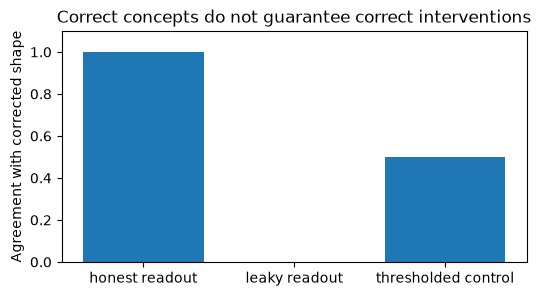

In [ ]:
concepts = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y = concepts[:,1].astype(int)
soft = np.column_stack([0.1 + 0.8*concepts[:,0] + 0.1*(2*concepts[:,1]-1), 0.1+0.8*concepts[:,1]])
corrected = correct_concept(soft, 1, 1-y)
leaky_before = leakage_readout(soft)
leaky_after = leakage_readout(corrected)
honest_after = (concept_readout(corrected, np.array([[0.],[1.]]), [0.])[:,0] >= .5).astype(int)
print("Thresholded concept accuracy:", binary_accuracy((soft >= .5).astype(int), concepts))
print("Respect opposite-shape correction: honest / leaky =", binary_accuracy(honest_after, 1-y), binary_accuracy(leaky_after, 1-y))
fig, ax = plt.subplots(figsize=(6,3))
ax.bar(['honest readout','leaky readout','thresholded control'], [binary_accuracy(honest_after,1-y), binary_accuracy(leaky_after,1-y), binary_accuracy(leakage_readout((corrected>=.5).astype(float)),1-y)])
ax.set(ylim=(0,1.1), ylabel='Agreement with corrected shape',title='Correct concepts do not guarantee correct interventions')
plt.show()

<details><summary>Expected output</summary>

`Thresholded concept accuracy: 1.0`; the honest readout respects all opposite-shape corrections, while the leaky readout respects none. Hard thresholding destroys this particular side channel but our malicious decoder then collapses to a constant: that control agrees on half the cases. Thresholding alone has not repaired the decoder.

</details>

<details><summary>Help - why is this not a contradiction?</summary>

Concept accuracy evaluates the original predictions. Intervention agreement evaluates a different computation after a named coordinate changes. We intentionally retained the color coordinate’s hidden shape information. A model trained only on observational pairs need never learn what to do after the independent correction.

</details>

## Summary of 1️⃣
You built both the intervention and a counterexample to the claim that accurate concepts guarantee a faithful bottleneck. Next we will examine a stronger algebraic editing promise.

# 2️⃣ Contextual mixtures of fixed senses

> ##### Learning Objectives
>
> - Predict the exact effect of a sense edit and measure its collateral effect.

A Backpack LM stores $K$ non-contextual sense vectors per token, $C[v,k,:]$. Its contextualization network supplies weights $\alpha[k,i,j]$ over source positions $j\le i$ for each target position $i$ and sense $k$. The representation is
$$h_i=\sum_{k=1}^{K}\sum_{j\le i}\alpha[k,i,j] C[x_j,k,:],\qquad \ell_i=h_i U.$$
Here $U$ has shape `[hidden, vocabulary]`. **Each sense has its own distribution over source positions**. Do not normalize over both senses and positions. “Sense” need not mean a dictionary word sense; it is a learned non-contextual vector. Our named finance/river vectors are a pedagogical choice.

We will use supplied contextualization scores for two sequences, `bank loan` and `bank river`. This implements the released architecture’s readout decomposition and edit algebra, while omitting its learned contextualization transformer and language-model training. The resulting word predictions are exact designed fixtures, not evidence of learned semantics.

### Exercise - implement `causal_weights`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Scores have shape `[sense, target_position, source_position]`, with equal source and target length. Apply a causal mask and softmax over source positions independently per sense. Future weights must be exactly zero.

In [ ]:
def causal_weights(scores):
    raise NotImplementedError()


tests.test_causal_weights(causal_weights)

<details><summary>Hint</summary>

Build a lower-triangular mask. Subtract the row maximum before exponentiating.

</details>

<details><summary>Help - why does this matter?</summary>

Context can choose which stored vector contributes through the source weights; changing token senses changes a global reusable hook.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_causal_weights passed!`.
For two zero-score positions, each sense has rows `[1,0]` and `[0.5,0.5]`.

</details>


<details><summary>Solution</summary>

```python
def causal_weights(scores):
    scores = np.asarray(scores, dtype=float)
    n = scores.shape[-1]
    masked = np.where(np.tril(np.ones((n,n), dtype=bool)), scores, -np.inf)
    shift = masked - np.max(masked, axis=-1, keepdims=True)
    weights = np.exp(shift)
    return weights / weights.sum(axis=-1, keepdims=True)
```
</details>

### Exercise - implement `backpack_hidden`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Combine token IDs `[position]`, stored senses `[vocabulary,sense,hidden]` and weights `[sense,target,source]` into `[target,hidden]`. Sum source and sense axes, preserving target.

In [ ]:
def backpack_hidden(token_ids, senses, alpha):
    raise NotImplementedError()


tests.test_backpack_hidden(backpack_hidden)

<details><summary>Hint</summary>

After indexing the senses, the axes are `j,k,d`.

</details>

<details><summary>Help - why does this matter?</summary>

This sum, rather than a contextual vector for each token, is the architectural interpretability hook.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_backpack_hidden passed!`.
With one token and two senses `[1,2]` and `[3,4]`, both unit weighted, its hidden vector is `[4,6]`.

</details>


<details><summary>Solution</summary>

```python
def backpack_hidden(token_ids, senses, alpha):
    return np.einsum("kij,jkd->id", alpha, np.asarray(senses)[np.asarray(token_ids)])
```
</details>

### Exercise - implement `sense_readout`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Project every stored sense into output-token logits; preserve the vocabulary and sense axes. This readout is non-contextual.

In [ ]:
def sense_readout(senses, unembedding):
    raise NotImplementedError()


tests.test_sense_readout(sense_readout)

<details><summary>Hint</summary>

NumPy broadcasts matrix multiplication over leading dimensions.

</details>

<details><summary>Help - why does this matter?</summary>

A top-token list is a property of a fixed sense under a fixed output map, not a claim that the vector has a single semantic meaning.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_sense_readout passed!`.
An identity unembedding leaves each sense unchanged.

</details>


<details><summary>Solution</summary>

```python
def sense_readout(senses, unembedding):
    return np.asarray(senses) @ np.asarray(unembedding)
```
</details>

### Exercise - implement `edit_sense`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Add a hidden-space vector `delta` to exactly one stored token/sense vector. Return a copy; all other entries must remain byte-for-byte numerically unchanged.

In [ ]:
def edit_sense(senses, token, sense, delta):
    raise NotImplementedError()


tests.test_edit_sense(edit_sense)

<details><summary>Hint</summary>

Use the two categorical indices before the hidden axis.

</details>

<details><summary>Help - why does this matter?</summary>

This is a global lexical edit: every later occurrence of the token may be affected, even in a context you did not intend.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_edit_sense passed!`.
A unit edit changes one vector; the original array stays unchanged.

</details>


<details><summary>Solution</summary>

```python
def edit_sense(senses, token, sense, delta):
    edited = np.array(senses, dtype=float, copy=True)
    edited[token, sense] += np.asarray(delta)
    return edited
```
</details>

### Exercise - implement `predicted_edit_delta`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Predict the output-logit change without recomputing the full representation. Sum the edited sense’s contextual weight over **all occurrences** of the edited token; multiply by `delta @ U`. Return `[target,output]`.

In [ ]:
def predicted_edit_delta(token_ids, alpha, token, sense, delta, unembedding):
    raise NotImplementedError()


tests.test_predicted_edit_delta(predicted_edit_delta)

<details><summary>Hint</summary>

Select the edited sense first. Its matrix is `[target, source]`; select matching source columns and sum the source axis.

</details>

<details><summary>Help - why does this matter?</summary>

The linear prediction is exact only if alpha and U stay fixed. An intervention on the contextualizer has a different contract.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_predicted_edit_delta passed!`.
If edited-token mass is `0.25` and the edit projects to `[2,-1]`, the logit delta is `[0.5,-0.25]`.

</details>


<details><summary>Solution</summary>

```python
def predicted_edit_delta(token_ids, alpha, token, sense, delta, unembedding):
    mass = np.asarray(alpha)[sense][:, np.asarray(token_ids) == token].sum(axis=-1)
    return mass[:,None] * (np.asarray(delta) @ np.asarray(unembedding))[None,:]
```
</details>

In [ ]:
senses = np.zeros((3,2,2))
senses[0] = [[3.,0.],[0.,3.]]  # bank; loan and river carry no fixture signal
U = np.eye(2)  # output labels: money, water
contexts = {'bank loan': np.array([0,1]), 'bank river':np.array([0,2])}
context_scores = {}
for name in contexts:
    score = np.zeros((2,2,2))
    score[:,1,0] = [np.log(9), -np.log(9)] if name=='bank loan' else [-np.log(9), np.log(9)]
    context_scores[name] = causal_weights(score)
edit_delta = np.array([-2.,0.])
edited = edit_sense(senses, 0, 0, edit_delta)
for name, ids in contexts.items():
    alpha = context_scores[name]
    before = backpack_hidden(ids,senses,alpha) @ U
    after = backpack_hidden(ids,edited,alpha) @ U
    oracle = predicted_edit_delta(ids,alpha,0,0,edit_delta,U)
    assert np.allclose(after-before,oracle)
    print(name, 'before / after final logits:', before[-1], after[-1])
print('Non-contextual bank sense logits:', sense_readout(senses,U)[0])

<details><summary>Expected output</summary>

`bank loan` changes from `[2.7,0.3]` to `[0.9,0.3]`. `bank river` changes from `[0.3,2.7]` to `[0.1,2.7]`. The finance edit has a smaller, **nonzero** effect in the river context because its finance-sense weight is 0.1, not zero.

</details>

## Summary of 2️⃣
The edit is global in parameter space and context-weighted in output space. The exact delta formula exposes collateral effects; good sense names do not make edits perfectly local.

# 3️⃣ Train for counterfactuals

> ##### Learning Objectives
>
> - Fit a tiny readout on counterfactual rows and compare with observation-only fitting.

A causal calculator receives $(a,b)\in\{0,1\}^2$ and returns $y=2a+b$. Its hidden state is $h=(a,b)Q^\top$, where $Q$ is an orthogonal rotation. The direction for $a$ is $d=Q[:,0]$. Replacing only this causal variable with a donor’s value should produce $2a_{donor}+b_{base}$.

For a unit vector $d$, the low-level interchange is
$$h^{swap}=h^{base}+\big[(h^{donor}-h^{base})d\big]d^\top.$$
The row-vector shapes are `[batch,hidden]`, `[hidden]`, and `[batch,1]` for the projected difference. The base keeps its perpendicular component. This is the same operation as a one-dimensional distributed alignment patch in 11.3; here the alignment is **given**, not searched or validated with DAS.

Observation-only examples contain just `(0,0)` and `(1,1)`. They cannot distinguish the correct rule `2a+b` from `1.5a+1.5b`. Counterfactual rows break this correlation. IIT uses the high-level model’s swapped outcomes as training targets for the correspondingly patched low-level network. Our least-squares readout is the smallest exact instance of that objective.

### Exercise - implement `swap_subspace`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the donor component along a unit direction and the base component perpendicular to it. Support a single hidden vector or matching batches. Reject a nonunit direction.

In [ ]:
def swap_subspace(base, donor, direction):
    raise NotImplementedError()


tests.test_swap_subspace(swap_subspace)

<details><summary>Hint</summary>

Only the difference between donor and base projections is added.

</details>

<details><summary>Help - why does this matter?</summary>

Copying the whole donor would change b as well as a, giving the right answer for the wrong intervention.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_swap_subspace passed!`.
Swapping `[1,4]` toward donor `[3,9]` along `[1,0]` gives `[3,4]`.

</details>


<details><summary>Solution</summary>

```python
def swap_subspace(base, donor, direction):
    direction = np.asarray(direction, dtype=float)
    if not np.isclose(direction @ direction, 1.0):
        raise ValueError("direction must have unit norm")
    base = np.asarray(base)
    return base + ((np.asarray(donor)-base) @ direction)[...,None]*direction
```
</details>

### Exercise - implement `causal_target`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement the abstract model after interchanging a. Keep the base’s b. The optional coefficient supports the changed-rule experiment.

In [ ]:
def causal_target(base_concepts, donor_concepts, a_weight=2.0):
    raise NotImplementedError()


tests.test_causal_target(causal_target)

<details><summary>Hint</summary>

The donor supplies the first coordinate only.

</details>

<details><summary>Help - why does this matter?</summary>

The training target must come from the abstract intervention, not from the model you are trying to train.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_causal_target passed!`.
Base `(0,1)`, donor `(1,0)` produces `3` for coefficient 2.

</details>


<details><summary>Solution</summary>

```python
def causal_target(base_concepts, donor_concepts, a_weight=2.0):
    return a_weight*np.asarray(donor_concepts)[...,0] + np.asarray(base_concepts)[...,1]
```
</details>

### Exercise - implement `interchange_rows`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Enumerate all ordered base/donor pairs in base-major order. Return patched hidden rows `[n*n,hidden]` and abstract targets `[n*n]`. Use the preceding visible functions.

In [ ]:
def interchange_rows(concepts, rotation, direction, a_weight=2.0):
    raise NotImplementedError()


tests.test_interchange_rows(interchange_rows)

<details><summary>Hint</summary>

Repeat each base n times and tile the full donor list n times.

</details>

<details><summary>Help - why does this matter?</summary>

Testing all pairs prevents reporting one cherry-picked successful swap. Self-pairs provide a no-change baseline.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_interchange_rows passed!`.
For all four binary concept rows, there are 16 patched rows. With correct alignment every row matches its high-level target.

</details>


<details><summary>Solution</summary>

```python
def interchange_rows(concepts, rotation, direction, a_weight=2.0):
    concepts = np.asarray(concepts, dtype=float)
    hidden = concepts @ np.asarray(rotation).T
    base = np.repeat(hidden, len(hidden), axis=0)
    donor = np.tile(hidden, (len(hidden),1))
    base_c = np.repeat(concepts,len(concepts),axis=0)
    donor_c = np.tile(concepts,(len(concepts),1))
    return swap_subspace(base,donor,direction), causal_target(base_c,donor_c,a_weight)
```
</details>

### Exercise - implement `fit_readout`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Fit a zero-intercept scalar readout by least squares. `features` is `[examples,hidden]`; return `[hidden]`. The zero-zero case justifies omitting an intercept on this exact task.

In [ ]:
def fit_readout(features, targets):
    raise NotImplementedError()


tests.test_fit_readout(fit_readout)

<details><summary>Hint</summary>

Use the minimum-norm `lstsq` solution; do not invert a singular Gram matrix.

</details>

<details><summary>Help - why does this matter?</summary>

The observational design is rank deficient. Minimum norm resolves the numerical problem but cannot supply missing causal evidence.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_fit_readout passed!`.
Features `[[1,0],[0,1]]`, targets `[2,3]` yield `[2,3]`.

</details>


<details><summary>Solution</summary>

```python
def fit_readout(features, targets):
    return np.linalg.lstsq(np.asarray(features), np.asarray(targets), rcond=None)[0]
```
</details>

### Exercise - implement `interchange_agreement`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Measure the fraction of scalar counterfactual values equal within absolute tolerance. This is interchange intervention **value** agreement on a regression calculator, not classification IIA on the paper’s tasks.

In [ ]:
def interchange_agreement(predictions, targets, atol=1e-8):
    raise NotImplementedError()


tests.test_interchange_agreement(interchange_agreement)

<details><summary>Hint</summary>

Use `isclose` with zero relative tolerance and average.

</details>

<details><summary>Help - why does this matter?</summary>

Low MSE and exact counterfactual agreement answer different questions. One unusually large error can dominate MSE.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_interchange_agreement passed!`.
Predictions `[0,1,2.1]`, targets `[0,1,2]` give agreement `2/3` at tolerance `1e-8`.

</details>


<details><summary>Solution</summary>

```python
def interchange_agreement(predictions, targets, atol=1e-8):
    return float(np.mean(np.isclose(predictions, targets, atol=atol, rtol=0)))
```
</details>

In [ ]:
Q = np.array([[1.,-1.],[1.,1.]])/np.sqrt(2)
direction = Q[:,0]
observed = np.array([[0.,0.],[1.,1.]])
all_concepts = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
obs_h = observed @ Q.T
obs_y = 2*observed[:,0]+observed[:,1]
w_observed = fit_readout(obs_h,obs_y)
train_h, train_y = interchange_rows(observed,Q,direction)
w_iit = fit_readout(np.concatenate([obs_h,train_h]),np.concatenate([obs_y,train_y]))
audit_h,audit_y = interchange_rows(all_concepts,Q,direction)
wrong_h,_ = interchange_rows(all_concepts,Q,Q[:,1])
pred_observed = audit_h @ w_observed
pred_iit = audit_h @ w_iit
print('Readout in concept coordinates: observational / IIT', Q.T @ w_observed, Q.T @ w_iit)
print('All-pair interchange agreement: observational / IIT / wrong subspace', interchange_agreement(pred_observed,audit_y),interchange_agreement(pred_iit,audit_y),interchange_agreement(wrong_h @ w_iit,audit_y))
print('Observation-only fitting residual:', np.max(np.abs(obs_h @ w_observed-obs_y)))

<details><summary>Expected output</summary>

The concept-coordinate coefficients are `[1.5,1.5]` and `[2,1]`. Observation-only fitting has zero residual on its two supplied points. Its causal interpretation still fails when the concept values differ. Exact agreement values are computed in the audit immediately below.

</details>

## Summary of 3️⃣
The IIT objective supplies information absent from correlated observational examples. Known alignment plus correct abstract targets identifies this two-parameter readout. It has not established that a learned representation will admit such an alignment.

# 4️⃣ Audit the intervention

> ##### Learning Objectives
>
> - Predict a changed causal rule before recomputing the tiny fit.

For all 16 base/donor pairs, predict which rows will fail for the observational readout. Its prediction is `1.5 * donor_a + 1.5 * base_b`; the target is `2 * donor_a + base_b`. The error is therefore `0.5 * (base_b - donor_a)`. Write the agreement fraction and the signs of the two off-diagonal errors.

The three-panel dashboard below is the section’s primary signature result. Its color scales are shared across the two heatmaps. The third panel checks the Backpack edit formula and shows the wrong-sense control on the same axes.


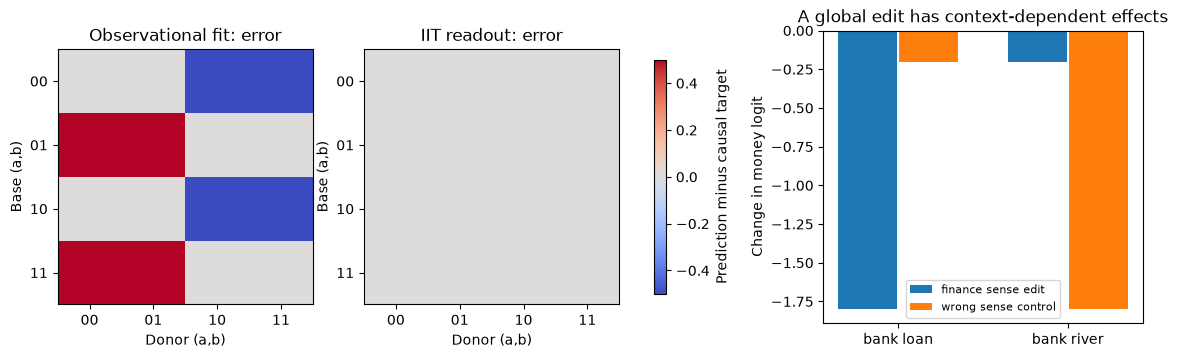

In [ ]:
fig, axes = plt.subplots(1,3,figsize=(14,3.8))
labels = ['00','01','10','11']
for ax, pred, title in zip(axes[:2],[pred_observed,pred_iit],['Observational fit: error','IIT readout: error']):
    im=ax.imshow((pred-audit_y).reshape(4,4),vmin=-.5,vmax=.5,cmap='coolwarm')
    ax.set(xticks=range(4),xticklabels=labels,yticks=range(4),yticklabels=labels,xlabel='Donor (a,b)',ylabel='Base (a,b)',title=title)
fig.colorbar(im,ax=list(axes[:2]),label='Prediction minus causal target',shrink=.8)
edit_effect=[]; wrong_effect=[]
wrong_edit=edit_sense(senses,0,1,edit_delta)
for name,ids in contexts.items():
    alpha=context_scores[name]
    original=backpack_hidden(ids,senses,alpha)@U
    edit_effect.append((backpack_hidden(ids,edited,alpha)@U-original)[-1,0])
    wrong_effect.append((backpack_hidden(ids,wrong_edit,alpha)@U-original)[-1,0])
x=np.arange(2)
axes[2].bar(x-.18,edit_effect,width=.35,label='finance sense edit')
axes[2].bar(x+.18,wrong_effect,width=.35,label='wrong sense control')
axes[2].set(xticks=x,xticklabels=list(contexts),ylabel='Change in money logit',title='A global edit has context-dependent effects')
axes[2].legend(fontsize=8)
plt.show()
print('All-pair agreement:', interchange_agreement(pred_observed,audit_y), interchange_agreement(pred_iit,audit_y), interchange_agreement(wrong_h@w_iit,audit_y))

## Interpreting the result

<details><summary>Help - how should I interpret this?</summary>

The observational map has errors of ±0.5 when donor a differs from base b, despite perfect fit on the correlated observations. The IIT map is zero to floating precision. A wrong-subspace patch is evaluated against the same a-interchange targets, so it must fail even though its values are mathematically legitimate b-interchanges. The Backpack control changes the wrong sense: in `bank river` it has a larger effect than the intended finance edit. That is a contextual weighting property, not random noise.

A surprising result is the leaky bottleneck’s perfect concept accuracy in part 1. Explain why neither that score nor an attractive non-contextual sense readout is sufficient evidence of intervention faithfulness. Each headline operation here is paired with a control designed to expose a particular failure.

</details>

## Try it yourself

Change only the high-level coefficient from 2 to 4. Before running, predict the observational minimum-norm coefficients and its all-pair agreement. Will it improve because the two supplied training labels become larger? Keep the hidden rotation fixed.


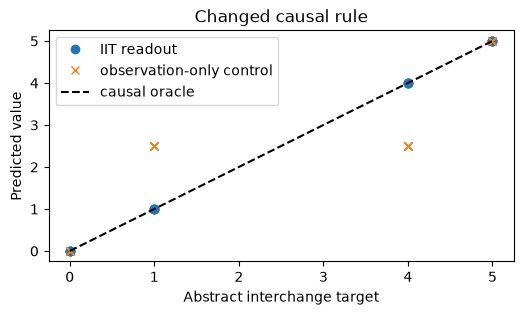

In [ ]:
a_weight = 4.0  # editable causal rule, not a new random seed
obs_new = a_weight*observed[:,0]+observed[:,1]
w_obs_new = fit_readout(obs_h,obs_new)
train_new_h,train_new_y = interchange_rows(observed,Q,direction,a_weight)
w_iit_new = fit_readout(np.concatenate([obs_h,train_new_h]),np.concatenate([obs_new,train_new_y]))
audit_new_h,audit_new_y = interchange_rows(all_concepts,Q,direction,a_weight)
print('New concept-coordinate coefficients:',Q.T@w_obs_new,Q.T@w_iit_new)
print('New agreement:',interchange_agreement(audit_new_h@w_obs_new,audit_new_y),interchange_agreement(audit_new_h@w_iit_new,audit_new_y))
fig,ax=plt.subplots(figsize=(6,3))
ax.plot(audit_new_y,audit_new_h@w_iit_new,'o',label='IIT readout')
ax.plot(audit_new_y,audit_new_h@w_obs_new,'x',label='observation-only control')
ax.plot([0,a_weight+1],[0,a_weight+1],'k--',label='causal oracle')
ax.set(xlabel='Abstract interchange target',ylabel='Predicted value',title='Changed causal rule')
ax.legend();plt.show()

<details><summary>Expected output for the default play</summary>

The observational coefficients become `[2.5,2.5]`; IIT gives `[4,1]`. Increasing the causal asymmetry increases the magnitude of off-diagonal mistakes, but exact agreement remains 0.5 versus 1.0. The wrong-subspace control in the original rule has agreement 0.25.

</details>

## Summary of 4️⃣
You can now distinguish an accurate label, an interpretable-looking coordinate, an algebraically predictable edit and a faithful causal interchange. The contracts differ; design controls for the claim you actually need.

## Limitations

These finite examples establish component algebra and a leakage possibility. There is no pretrained language model, learned image-concept extractor, human concept validation, natural-text edit evaluation, learned contextualizer or independent evaluation dataset. The two-point least-squares IIT example uses a known alignment and complete analytic causal supervision. It does not run the released IIT training pipeline or DAS; full network training and the 11.3 alignment verification remain pending. All enumerated points and public expected outputs are seen teaching fixtures. A zero audit error on them is exact-task correctness, not generalization.

# ☆ Bonus

Try constructing a nonlinear leakage decoder that survives quantization into three bins. Which assumption does hard thresholding actually enforce? For Backpack editing, alter the contextualization scores as well as the stored sense: explain why the old delta formula then fails. For IIT, rotate the patch direction by an angle and predict which interchange identities survive before measuring them.

## Further Reading

- [Koh et al., Concept Bottleneck Models](https://proceedings.mlr.press/v119/koh20a.html): concepts as an intervention interface; sequential, independent and joint training have different consequences.
- [Mahinpei et al., Do Concept Bottleneck Models Learn as Intended?](https://arxiv.org/abs/2105.04289): information leakage through concept representations.
- [Hewitt et al., Backpack Language Models](https://aclanthology.org/2023.acl-long.506/): non-contextual sense vectors combined by contextual weights; learned senses need not be dictionary senses.
- [Geiger et al., Inducing Causal Structure for Interpretable Neural Networks](https://proceedings.mlr.press/v162/geiger22a.html): train aligned neural interchanges against high-level counterfactual labels.
- [ARENA 11.3: causal abstraction and DAS](../../../chapter11_representation_geometry/exercises/part3_causal_abstraction_das/): searching for an alignment is a separate step from training the aligned behavior.